# Parallel Cellular Algorithm for Image Processing

This notebook demonstrates a simple **Cellular Automaton / Parallel Cellular Algorithm** for cleaning a binary image.

Each pixel is treated as a cell. A pixel looks at its 8 neighboring pixels. If at least 4 neighbors are black, the pixel becomes black; otherwise it becomes white.


## 1. Import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files


## 2. Create a simple test image

This creates a black object with some random noise so we can see the cellular rule in action.

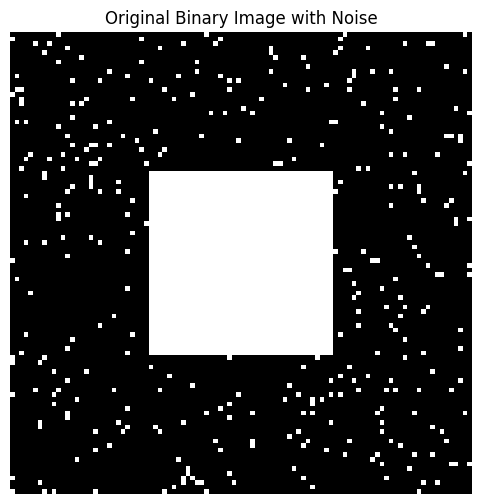

In [ ]:
np.random.seed(42)

# White background
image = np.zeros((100, 100), dtype=np.uint8)

# Create a black square in the middle
image[30:70, 30:70] = 1

# Add random black noise
noise = np.random.rand(100, 100) < 0.04
image[noise] = 1

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray', vmin=0, vmax=1)
plt.title('Original Binary Image with Noise')
plt.axis('off')
plt.show()


## 3. Cellular Automaton rule

For every pixel:

- Look at the 8 neighboring pixels.
- Count how many are black (`1`).
- If 4 or more neighbors are black, make the current pixel black.
- Otherwise make it white.

All pixels calculate their new states from the **old image**, which is what makes the rule suitable for parallel execution.

In [ ]:
def cellular_update(image):
    """Apply one cellular automaton iteration."""
    padded = np.pad(image, 1, mode='constant', constant_values=0)

    # Count the 8 neighbors for every pixel.
    neighbor_count = (
        padded[:-2, :-2] + padded[:-2, 1:-1] + padded[:-2, 2:] +
        padded[1:-1, :-2] + padded[1:-1, 2:] +
        padded[2:, :-2] + padded[2:, 1:-1] + padded[2:, 2:]
    )

    # Cellular rule: 4 or more black neighbors -> black.
    new_image = (neighbor_count >= 4).astype(np.uint8)

    return new_image


## 4. Run one iteration

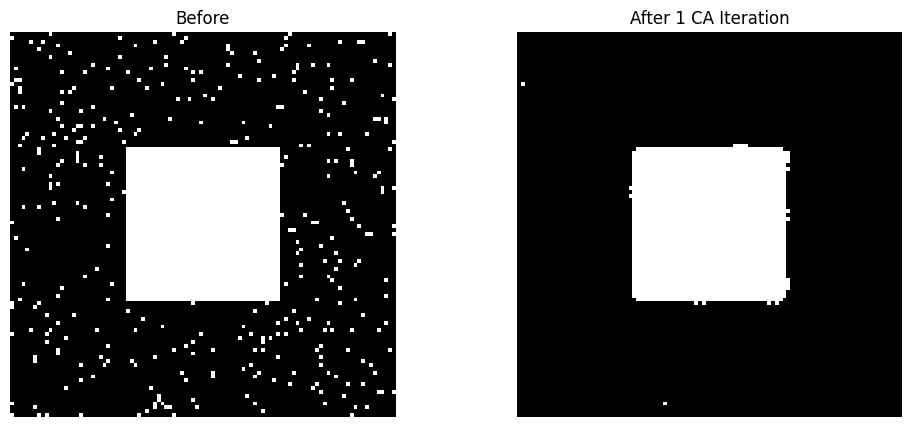

In [ ]:
result = cellular_update(image)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=1)
plt.title('Before')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result, cmap='gray', vmin=0, vmax=1)
plt.title('After 1 CA Iteration')
plt.axis('off')

plt.show()


## 5. Run multiple iterations

Try changing `iterations` to see how repeated local updates change the image.

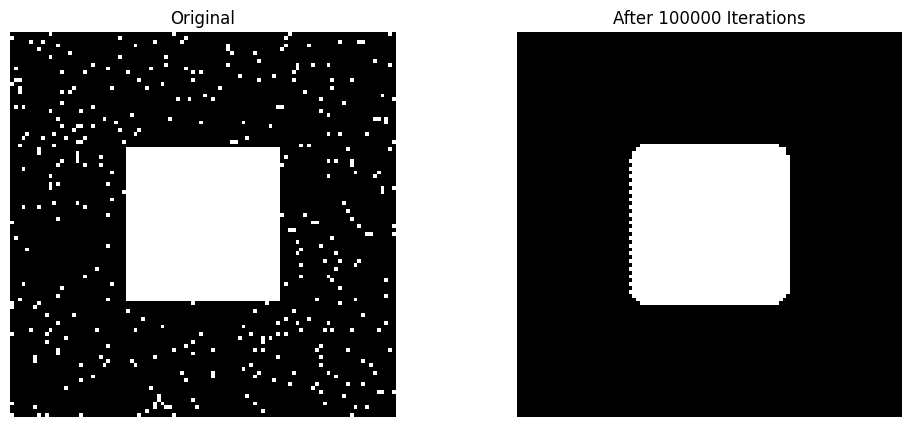

In [ ]:
iterations = 100000
processed = image.copy()

for _ in range(iterations):
    processed = cellular_update(processed)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=1)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(processed, cmap='gray', vmin=0, vmax=1)
plt.title(f'After {iterations} Iterations')
plt.axis('off')

plt.show()


## 6. Test with your own image

Run this cell and upload an image. It will convert the image to grayscale and then to a binary black/white image.

Saving Screenshot 2026-09-30 130715.png to Screenshot 2026-09-30 130715 (4).png


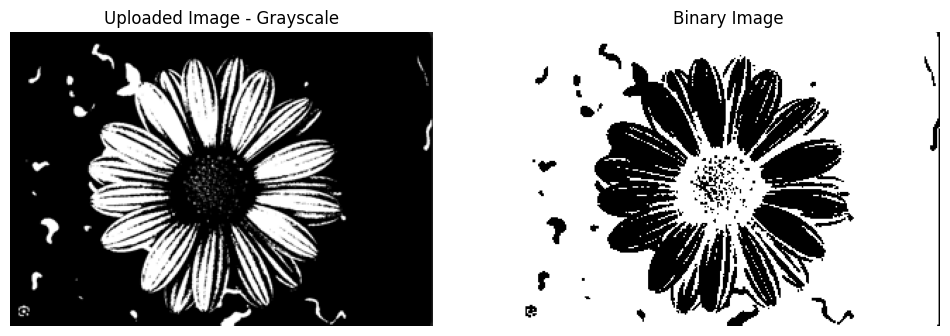

In [ ]:
uploaded = files.upload()

filename = next(iter(uploaded))
img = Image.open(filename).convert('L')

# Resize to keep processing fast in Colab.
max_size = 300
img.thumbnail((max_size, max_size))

gray = np.array(img)

# Convert grayscale to binary.
# Pixels darker than 128 become black (1), others become white (0).
binary = (gray < 20).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Uploaded Image - Grayscale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap='gray', vmin=0, vmax=1)
plt.title('Binary Image')
plt.axis('off')

plt.show()


## 7. Apply the PCA/Cellular Automaton to your image

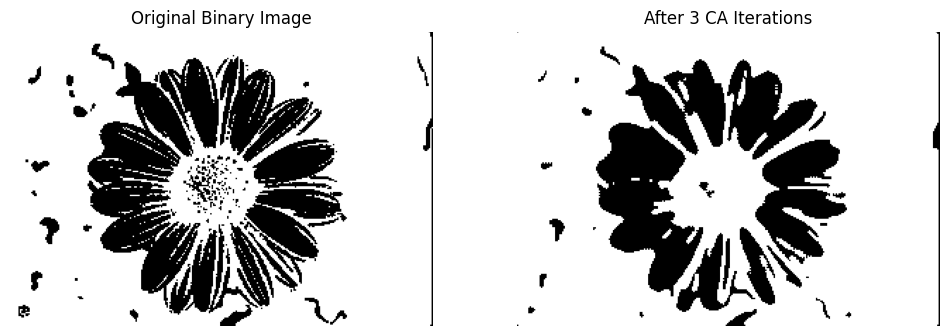

In [ ]:
iterations = 3
processed = binary.copy()

for _ in range(iterations):
    processed = cellular_update(processed)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap='gray', vmin=0, vmax=1)
plt.title('Original Binary Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(processed, cmap='gray', vmin=0, vmax=1)
plt.title(f'After {iterations} CA Iterations')
plt.axis('off')

plt.show()


## 8. Experiment

Try changing these values:

```python
iterations = 1
iterations = 3
iterations = 5
iterations = 10
```

You can also change the rule inside `cellular_update()` from:

```python
neighbor_count >= 4
```

to:

```python
neighbor_count >= 3
```

or:

```python
neighbor_count >= 5
```

and observe how the image changes.

## Summary

The implementation follows the PCA idea:

1. **Cells:** individual image pixels.
2. **State:** each pixel is 0 (white) or 1 (black).
3. **Neighborhood:** the 8 surrounding pixels.
4. **Update rule:** 4 or more black neighbors makes the pixel black.
5. **Parallelism:** every pixel can calculate its new state independently from the previous image.
6. **Iteration:** repeat the update several times to produce the processed image.